# 03. 금리 모형 (Vasicek)

**목표:** 앞으로 3년 동안 금리가 어떻게 움직일 수 있는지, **수천 개의 가능한 경로**를 만드는 모형을 세운다. 이 경로들이 6단계 몬테카를로 시뮬레이션의 재료가 된다.
- 이번 노트북의 모형은 "실제로 일어날 법한" 금리 경로를 만드는 **시나리오 생성용**이다. 플로어 **가격**을 매기는 모형은 다음 단계에서 따로 다룬다.

## Vasicek 모형이란

$$dr = a\,(b - r)\,dt + \sigma\,dW$$

말로 풀면: **금리의 변화 = (평균으로 끌려가는 힘) + (무작위 흔들림)**

| 기호 | 이름 | 직관 |
|---|---|---|
| **b** | 장기 평균 | 금리가 오래 지나면 돌아가려는 **기준점** (%) |
| **a** | 평균회귀 속도 | 기준점으로 끌려가는 **힘의 세기**. 고무줄이 얼마나 팽팽한지 |
| **σ** | 변동성 | 매 순간 생기는 **무작위 흔들림**의 크기 (%p / √년) |

- 금리가 b보다 높으면 a(b − r) < 0이라 아래로 끌리고, 낮으면 위로 끌린다.
- dW는 "동전 던지기" 같은 무작위 충격이다. σ가 클수록 경로가 더 들쭉날쭉하다.

## 1. 준비

### 라이브러리와 경로
이 셀이 하는 일: 도구를 불러오고, 폴더 경로와 그래프 설정을 한다.

In [1]:
import sys
import inspect   # 함수의 코드를 화면에 출력하는 도구
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm   # 정규분포 계산용

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

### 금리 모형 함수 불러오기
이 셀이 하는 일: `src/rate_model.py`에 만들어 둔 추정·시뮬레이션 함수를 불러오고, **코드를 그대로 출력**해서 무엇을 하는지 본다.
- 이 함수들은 다음 단계(플로어 가격, 몬테카를로)에서도 계속 쓰기 때문에 `src/`에 따로 두었다.

In [2]:
from src.rate_model import fit_vasicek, sigma_from_resid, bond_B, simulate_vasicek, DT

print(inspect.getsource(fit_vasicek))
print(inspect.getsource(simulate_vasicek))

def fit_vasicek(r, dt=DT):
    """월간 금리 r(%, pandas Series)로 Vasicek 파라미터를 추정한다.

    r(t+1) = c + φ·r(t) + e 를 회귀(AR(1))한 뒤 Vasicek 파라미터로 바꾼다.
      a = −ln(φ) / dt,  b = c / (1 − φ),  σ = sd(e) · √(2a / (1 − φ²))
    반환: (파라미터 딕셔너리, 잔차 Series)
    """
    y = r.iloc[1:].to_numpy()    # 다음 달 금리
    x = r.iloc[:-1].to_numpy()   # 이번 달 금리
    res = sm.OLS(y, sm.add_constant(x)).fit()
    c, phi = res.params
    if not 0 < phi < 1:
        raise ValueError(f"φ = {phi:.4f}: 평균회귀가 없어 Vasicek으로 바꿀 수 없음")

    a = -np.log(phi) / dt
    b = c / (1 - phi)
    resid = pd.Series(res.resid, index=r.index[1:])
    sigma = sigma_from_resid(resid, a, phi)
    params = {
        "phi": phi, "a": a, "b": b, "sigma": sigma,
        "half_life_months": np.log(2) / a * 12,   # 평균과의 거리가 절반으로 줄어드는 데 걸리는 개월 수
        "n": len(y), "start": r.index[0].date(), "end": r.index[-1].date(),
    }
    return params, resid

def simulate_vasicek(r0, a, b, sigma, months=36, n_paths=1000, seed=42, dt=DT):
    """r0(%)에

## 2. 데이터: 월간 기준금리
이 셀이 하는 일: 01번에서 만든 일별 기준금리(2018년 4월부터 SOFR, 그 전은 DFF)를 **월평균**으로 바꾼다. 2026년 10월은 아직 다 끝나지 않은 달이라 9월까지만 쓴다.

**왜 월말 값이 아니라 월평균인가?**
- SOFR는 **월말에 튀는** 경향이 있다(01번 노트북 1-6에서 확인). 월말 하루 값을 쓰면 이 튐이 "금리 변동"으로 잘못 잡혀 σ가 부풀려진다. (4번에서 실제로 비교한다)
- 02번 회귀에서도 금리는 월평균을 썼다. 같은 기준을 맞추는 의미도 있다.

In [3]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")

monthly_avg = rates["base_rate"].resample("ME").mean().loc[:"2026-09-30"]   # 월평균
monthly_end = rates["base_rate"].resample("ME").last().loc[:"2026-09-30"]   # 비교용: 월말 값

print("월간 기준금리:", monthly_avg.index[0].date(), "~", monthly_avg.index[-1].date(), f"({len(monthly_avg)}개월)")
monthly_avg.tail(3)

월간 기준금리: 2000-01-31 ~ 2026-09-30 (321개월)


date
2026-07-31   3.6200
2026-08-31   3.6419
2026-09-30   3.7464
Freq: ME, Name: base_rate, dtype: float64

## 3. AR(1) 회귀로 Vasicek 추정하기

Vasicek 모형을 한 달 간격으로 보면 아래 모양이 된다. "다음 달 금리를 이번 달 금리로 설명하는" 단순 회귀다. 이것을 **AR(1)**(1차 자기회귀: 자기 자신의 바로 전 값으로 설명)이라고 한다.

$$r_{t+1} = c + \varphi \, r_t + e_{t+1}$$

회귀로 c, φ, 잔차 e의 표준편차를 구하면 Vasicek 파라미터로 바꿀 수 있다.

| Vasicek | 계산식 | 직관 |
|---|---|---|
| a | −ln(φ) ÷ (1/12) | φ가 1에 가까울수록(금리가 지난달과 비슷할수록) a가 작다 = 천천히 돌아간다 |
| b | c ÷ (1 − φ) | 금리가 더 이상 안 변하는 지점 (r = c + φr 을 풀면 나옴) |
| σ | sd(e) × √(2a ÷ (1 − φ²)) | 매달 예상 밖 변화의 크기를 '연 단위'로 바꾼 것 |

- **반감기** = ln(2) ÷ a: 금리가 평균에서 벗어났을 때, 그 거리가 **절반으로 줄어드는 데 걸리는 시간**.

## 4. 추정: 메인(2000년~)과 민감도(2008년~)
이 셀이 하는 일: 두 기간으로 추정하고, 참고로 **월말 값**으로 추정한 결과도 함께 표로 비교한다.

In [4]:
fits = {
    "메인 (2000~, 월평균)":    fit_vasicek(monthly_avg.loc["2000":]),
    "민감도 (2008~, 월평균)":  fit_vasicek(monthly_avg.loc["2008":]),
    "참고 (2000~, 월말 값)":   fit_vasicek(monthly_end.loc["2000":]),
}

param_table = pd.DataFrame({name: p for name, (p, resid) in fits.items()}).T
param_table = param_table[["start", "end", "n", "phi", "a", "half_life_months", "b", "sigma"]]
param_table.columns = ["시작", "끝", "관측치", "φ", "a (평균회귀 속도)", "반감기(개월)", "b (장기 평균, %)", "σ (변동성)"]
param_table

,시작,끝,관측치,φ,a (평균회귀 속도),반감기(개월),"b (장기 평균, %)",σ (변동성)
"메인 (2000~, 월평균)",2000-01-31,2026-09-30,320,0.9923,0.0930,89.4674,1.3155,0.6366
"민감도 (2008~, 월평균)",2008-01-31,2026-09-30,224,0.9945,0.0666,124.9385,1.3272,0.6164
"참고 (2000~, 월말 값)",2000-01-31,2026-09-30,320,0.9875,0.1509,55.1127,1.5752,0.9211


**파라미터 읽는 법 (메인 기준)**
- **φ ≈ 0.992**: 이번 달 금리가 다음 달 금리를 거의 그대로 결정한다. 금리는 매우 '끈적한' 변수다.
- **a ≈ 0.09, 반감기 ≈ 89개월(약 7.5년)**: 금리가 장기 평균보다 2%p 높으면, 무작위 충격이 없다고 할 때 약 7.5년 뒤에 1%p 차이로 줄어든다. 평균으로 돌아가는 힘이 **약하다.** 3년 안에는 거리의 약 25%만 줄어든다.
- **b ≈ 1.3%**: 2000년 이후 금리가 돌아가려는 기준점. 낮아 보이는 이유는 **제로금리 기간이 약 9년**(2008~15년, 2020~22년)이나 되기 때문이다.
- **σ ≈ 0.64**: 무작위 흔들림만으로 1년에 약 ±0.64%p(1 표준편차), 한 달로 치면 약 ±0.18%p 움직인다.

**민감도 (2008년~)**: a가 더 작고(반감기 약 10년), b는 거의 같다(1.3%). 2008년 이후는 제로금리 비중이 더 커서 "평균으로 돌아가는 힘"이 더 약하게 잡힌다.

**참고 (월말 값)**: σ가 약 0.92로 월평균보다 **약 45% 크다.** 월말에 튀는 SOFR가 변동성으로 잘못 잡힌 결과다. 그래서 월평균을 쓴다.

> **주의:** φ가 1에 아주 가까울 때 AR(1) 추정은 a를 **크게(평균회귀를 빠르게)** 잡는 경향이 알려져 있다. 실제 평균회귀는 이보다 더 느릴 수 있다.

## 5. 최근 3년 변동성
이 셀이 하는 일: a와 b는 메인 추정값을 그대로 두고, **최근 36개월 잔차만으로** σ를 다시 계산한다.
- 장기와 최근 중 무엇을 쓸지에 따라 경로의 퍼짐이 달라진다.

In [5]:
main_p, main_resid = fits["메인 (2000~, 월평균)"]
recent_resid = main_resid.iloc[-36:]
sigma_recent = sigma_from_resid(recent_resid, main_p["a"], main_p["phi"])

pd.DataFrame({
    "기간":      [f"{main_resid.index[0]:%Y-%m} ~ {main_resid.index[-1]:%Y-%m}",
                 f"{recent_resid.index[0]:%Y-%m} ~ {recent_resid.index[-1]:%Y-%m}"],
    "σ":        [main_p["sigma"], sigma_recent],
    "한 달 흔들림(%p, 1σ)": [main_p["sigma"] * np.sqrt(DT), sigma_recent * np.sqrt(DT)],
}, index=["장기 (메인)", "최근 3년"])

,기간,σ,"한 달 흔들림(%p, 1σ)"
장기 (메인),2000-02 ~ 2026-09,0.6366,0.1838
최근 3년,2023-10 ~ 2026-09,0.3154,0.0910


**읽는 법**
- 최근 3년 σ(약 0.32)는 장기 σ(약 0.64)의 **절반**이다. 최근 3년에는 2008년이나 2020년 같은 급격한 인하가 없었기 때문이다.
- 최근 σ를 쓰면 **급락 위험이 작게** 잡힌다. 플로어는 바로 그 급락을 막는 도구다.

**결정: 기본은 장기 σ ≈ 0.64, 민감도는 최근 3년 σ ≈ 0.32.** 시나리오와 플로어 가격 계산에 **같은 σ**를 쓴다. σ가 다르면 플로어가 인위적으로 싸거나 비싸 보이기 때문이다.

## 5-2. 장기 평균 b: FOMC 전망

추정된 b ≈ 1.3%는 제로금리 약 9년에 끌려 내려간 값이다. 이 값을 쓰면 모든 경로가 아래로 끌려가서, 시장 선도금리(지금은 SOFR보다 높음)와 크게 어긋난다.

**결정: 기본 b = FOMC 장기 정책금리 전망 중위값, 스트레스 b = 과거 추정치 1.32%.** a와 σ는 추정값을 그대로 쓴다.
- **FOMC 장기 정책금리 전망**: 연준 위원들이 분기마다 "충격이 없을 때 장기적으로 적정한 기준금리"를 적어 내는 값(점도표)의 중위값이다. FRED 시리즈 `FEDTARMDLR`.

이 셀이 하는 일: FRED에서 `FEDTARMDLR`을 받아(`data/raw/fred/`) 최근 값들을 보여주고, 가장 최근 값을 기본 b로 정한다.
- 01번 노트북의 다운로드 함수와 같은 것을 `src/fred.py`에 두고 불러 쓴다.

In [6]:
from src.fred import download_fred, read_fred

download_fred("FEDTARMDLR")          # 이미 받은 파일이 있으면 건너뜀
fomc = read_fred("FEDTARMDLR").dropna()

b_fomc, b_fomc_date = fomc.iloc[-1], fomc.index[-1]
b_stress = main_p["b"]
print(f"기본 b (FOMC 장기 전망, {b_fomc_date:%Y-%m-%d} 발표) = {b_fomc:.2f}%")
print(f"스트레스 b (2000~ 과거 추정) = {b_stress:.2f}%")
fomc.tail(8).to_frame("FOMC 장기 전망 중위값(%)")

FEDTARMDLR 이미 받은 파일이 있어 건너뜀
기본 b (FOMC 장기 전망, 2026-09-16 발표) = 3.20%
스트레스 b (2000~ 과거 추정) = 1.32%


,FOMC 장기 전망 중위값(%)
observation_date,
2024-12-18,3.0000
2025-03-19,3.0000
2025-06-18,3.0000
2025-09-17,3.0000
2025-12-10,3.0000
2026-03-18,3.1000
2026-06-17,3.1000
2026-09-16,3.2000


## 6. 검증: 모형의 2년물 민감도 vs 실제 데이터

Vasicek 모형에서 2년물 금리는 단기금리 r의 함수다.

$$y_{2Y} = \frac{-\ln A(2) + B(2)\,r}{2}, \qquad B(\tau) = \frac{1 - e^{-a\tau}}{a}$$

따라서 **단기금리가 1%p 변하면 2년물은 B(2)/2 %p 변한다.** 이 값을 실제 데이터의 "Δ2년물을 ΔSOFR로 회귀한 기울기"와 비교한다.
- 이 값이 맞아야, 3단계 발행량 모형(Δ2년물 → 시장 변화)에 금리 모형을 연결할 수 있다.

### 모형 값
이 셀이 하는 일: 메인·민감도 추정의 a로 B(2)/2를 계산한다.

In [7]:
model_slope = {name: bond_B(2, p["a"]) / 2 for name, (p, _) in fits.items() if "월평균" in name}
pd.Series(model_slope, name="모형 B(2)/2").to_frame()

,모형 B(2)/2
"메인 (2000~, 월평균)",0.9125
"민감도 (2008~, 월평균)",0.9363


### 데이터 기울기
이 셀이 하는 일: SOFR가 있는 기간(2018-05 ~ 2026-09)의 월평균 데이터로 Δ2년물 = α + β·ΔSOFR 회귀를 돌린다. 변화 간격을 1개월, 3개월, 12개월로 바꿔 본다.
- 3개월·12개월은 기간이 겹치지 않게 3개월·12개월마다 하나씩만 쓴다. 그래서 관측치가 적다.
- 표준오차는 02번처럼 Newey-West로 계산한다.

In [8]:
sofr_2y = rates[["SOFR", "DGS2"]].resample("ME").mean().loc["2018-05":"2026-09"]

slope_rows = {}
for k in [1, 3, 12]:
    changes = sofr_2y.diff(k).dropna().iloc[::k]    # k개월 변화, 겹치지 않게
    res = sm.OLS(changes["DGS2"], sm.add_constant(changes["SOFR"])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    lo, hi = res.conf_int().loc["SOFR"]
    slope_rows[f"{k}개월 변화"] = {"데이터 기울기 β": res.params["SOFR"], "95% 하한": lo, "95% 상한": hi,
                                "관측치": int(res.nobs), "R²": res.rsquared}
slope_table = pd.DataFrame(slope_rows).T
slope_table["모형 B(2)/2 (메인)"] = model_slope["메인 (2000~, 월평균)"]
slope_table

,데이터 기울기 β,95% 하한,95% 상한,관측치,R²,모형 B(2)/2 (메인)
1개월 변화,0.4461,0.2034,0.6888,100.0000,0.1665,0.9125
3개월 변화,0.5587,0.3801,0.7372,33.0000,0.3446,0.9125
12개월 변화,0.5178,0.3068,0.7289,8.0000,0.5148,0.9125


**읽는 법**
- 모형은 "SOFR가 1%p 움직이면 2년물이 약 **0.91%p**" 움직인다고 본다. 실제 데이터는 약 **0.45~0.56%p**다. 모형이 2년물 반응을 **약 2배 크게** 본다. 신뢰구간도 0.91에 닿지 않는다.
- 이유
  1. **기대 선행**: 2년물은 앞으로의 금리 변화를 미리 반영한다. 그래서 SOFR가 실제로 움직이는 달에는 이미 상당 부분 움직인 뒤다. 1요인 모형은 이를 담지 못한다(CLAUDE.md에 적어 둔 한계).
  2. 평균회귀가 약하게 추정돼서(a 작음) B(2)/2가 1에 가깝게 나온다. 실제 시장은 "지금 금리 변화가 오래가지 않는다"고 더 강하게 보는 셈이다.
- **3단계와 연결할 때의 의미**: b1 = 0(보수) 시나리오에는 영향이 없다. b1 ≠ 0(기본·낙관)에서 모형 공식을 그대로 쓰면 2년물 변화가 실제보다 크게 잡혀 **자연 헤지를 약 2배 과대평가**하게 된다.

**결정: Δ2년물 = 0.5 × Δ단기금리 (데이터 기울기)를 쓴다.** 모형 공식(0.91)과 어긋나는 점은 1요인 모형의 한계로 기록한다.

## 7. 시험 시뮬레이션

### 경로 만들기
이 셀이 하는 일: **현재 SOFR**에서 시작해 **기본 설정**(a = 메인 추정, b = FOMC 장기 전망, σ = 장기 0.64)으로 3년(36개월) 금리 경로 1,000개를 만든다.
- 매달: 다음 달 금리 = 장기 평균 쪽으로 조금 이동 + 무작위 충격
- `seed=42`: 무작위 숫자를 매번 똑같이 뽑게 하는 설정. 다시 실행해도 같은 결과가 나온다.

In [9]:
sofr = rates["SOFR"].dropna()
r0, r0_date = sofr.iloc[-1], sofr.index[-1]

paths = simulate_vasicek(r0, main_p["a"], b_fomc, main_p["sigma"], months=36, n_paths=1000, seed=42)
expected_end = b_fomc + (r0 - b_fomc) * np.exp(-main_p["a"] * 3)   # 이론상 3년 뒤 평균

print(f"시작: SOFR {r0:.2f}% ({r0_date:%Y-%m-%d}) | 경로 {paths.shape[0]}개 × {paths.shape[1] - 1}개월")
print(f"3년 뒤 평균: 시뮬레이션 {paths[:, -1].mean():.2f}% / 이론값 {expected_end:.2f}%")

시작: SOFR 3.93% (2026-10-26) | 경로 1000개 × 36개월
3년 뒤 평균: 시뮬레이션 3.80% / 이론값 3.75%


### 경로 그래프
이 셀이 하는 일: 경로 50개를 옅은 선으로, 1,000개 경로의 **가운데 90% 범위**(5~95%)를 음영으로, 중앙값을 진한 선으로 그린다.

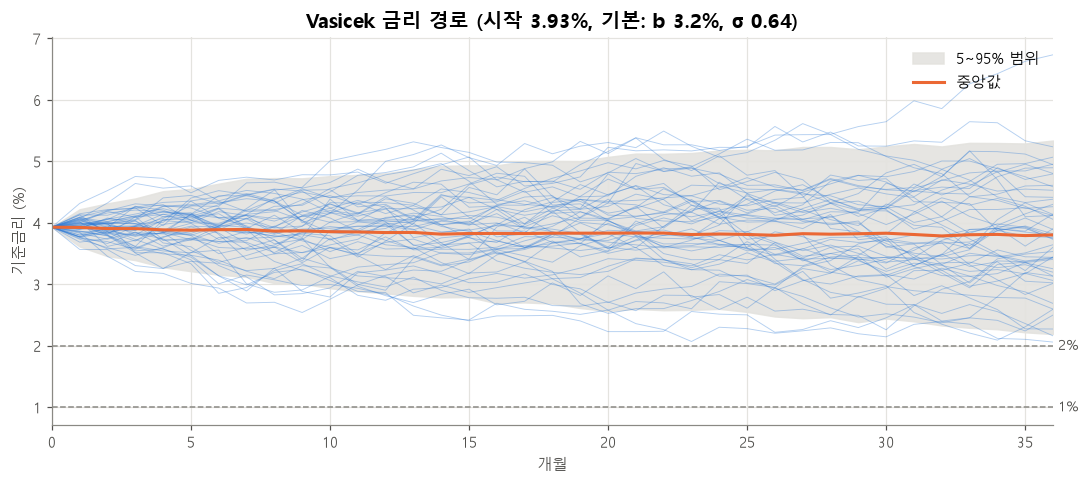

In [10]:
months = np.arange(paths.shape[1])
p5, p50, p95 = np.percentile(paths, [5, 50, 95], axis=0)

fig, ax = plt.subplots()
ax.fill_between(months, p5, p95, color=SHADE, alpha=0.9, label="5~95% 범위")
for path in paths[:50]:
    ax.plot(months, path, color=COLORS[0], linewidth=0.6, alpha=0.35)
ax.plot(months, p50, color=COLORS[1], linewidth=2, label="중앙값")
for level in (2, 1):
    ax.axhline(level, color=MUTED, linestyle="--", linewidth=1)
    ax.text(36, level, f" {level}%", va="center", color=TEXT_SUB, fontsize=9)

ax.set_xlim(0, 36)
ax.set_title(f"Vasicek 금리 경로 (시작 {r0:.2f}%, 기본: b {b_fomc:.1f}%, σ {main_p['sigma']:.2f})")
ax.set_xlabel("개월")
ax.set_ylabel("기준금리 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "4_vasicek_paths.png", dpi=200)
plt.show()

### 3년 뒤 금리 분포
이 셀이 하는 일: 1,000개 경로의 36개월 뒤 금리를 히스토그램으로 그린다.
- **히스토그램**: 값을 구간으로 나눠 각 구간에 몇 개가 들어가는지 막대로 그린 그림.

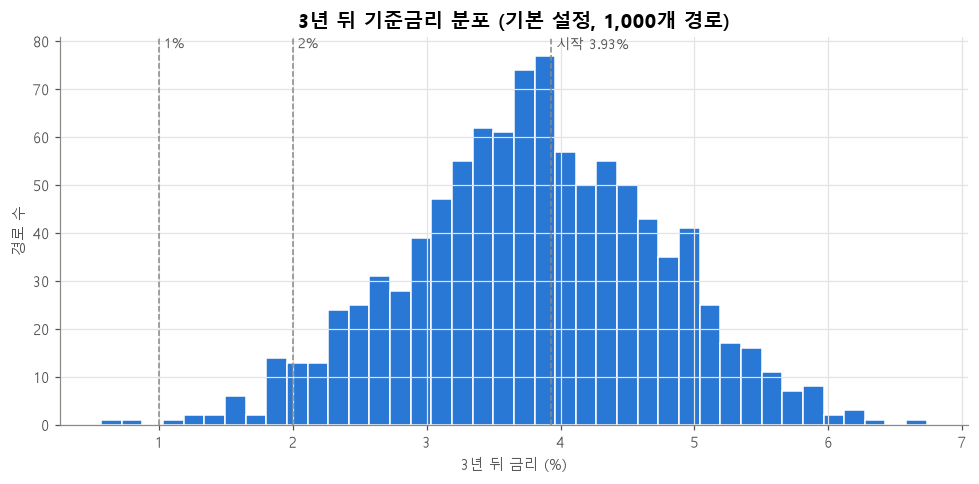

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(paths[:, -1], bins=40, color=COLORS[0], edgecolor="white", linewidth=1)
for level, label in [(r0, f"시작 {r0:.2f}%"), (2, "2%"), (1, "1%")]:
    ax.axvline(level, color=MUTED, linestyle="--", linewidth=1)
    ax.text(level, ax.get_ylim()[1], f" {label}", va="top", color=TEXT_SUB, fontsize=9)

ax.set_title("3년 뒤 기준금리 분포 (기본 설정, 1,000개 경로)")
ax.set_xlabel("3년 뒤 금리 (%)")
ax.set_ylabel("경로 수")
fig.tight_layout()
fig.savefig(FIG_DIR / "4_vasicek_terminal_hist.png", dpi=200)
plt.show()

### 금리가 2%, 1%, 0% 아래로 떨어지는 비율
이 셀이 하는 일: 여러 파라미터 조합으로 각각 1,000개 경로를 만들고 비율을 비교한다. 위 세 줄은 추정 그대로의 조합, 아래 세 줄은 **결정된 설정**(기본·민감도·스트레스)이다.
- 스트레스(b 1.32%, σ 0.64)는 a·b·σ가 "메인 (2000~)"과 같아서 결과도 같다. 비교하기 쉽게 이름을 붙여 따로 둔다.
- **"3년 안에 한 번이라도"**: 경로 중 어느 달이라도 그 아래로 내려간 적이 있는 비율 → 발행사가 한동안 저금리를 겪을 확률
- **"3년 뒤"**: 36개월째 값이 그 아래인 비율

In [12]:
PARAM_SETS = {
    "메인 (2000~)":           (main_p["a"], main_p["b"], main_p["sigma"]),
    "민감도 (2008~)":         (fits["민감도 (2008~, 월평균)"][0]["a"], fits["민감도 (2008~, 월평균)"][0]["b"],
                              fits["민감도 (2008~, 월평균)"][0]["sigma"]),
    "메인 + 최근 3년 σ":       (main_p["a"], main_p["b"], sigma_recent),
    "▶ 기본 (FOMC b, σ 0.64)":       (main_p["a"], b_fomc, main_p["sigma"]),
    "▶ 민감도 (FOMC b, σ 0.32)":      (main_p["a"], b_fomc, sigma_recent),
    "▶ 스트레스 (b 1.32%, σ 0.64)":   (main_p["a"], b_stress, main_p["sigma"]),
}

sim_rows = {}
sims = {}
for name, (a, b, sigma) in PARAM_SETS.items():
    sim = simulate_vasicek(r0, a, b, sigma, months=36, n_paths=1000, seed=42)
    sims[name] = sim
    path_min, end = sim.min(axis=1), sim[:, -1]
    sim_rows[name] = {
        "3년 뒤 5%":          np.percentile(end, 5),
        "3년 뒤 중앙값":        np.median(end),
        "3년 뒤 95%":         np.percentile(end, 95),
        "3년 안 <2% (%)":     (path_min < 2).mean() * 100,
        "3년 안 <1% (%)":     (path_min < 1).mean() * 100,
        "3년 안 <0% (%)":     (path_min < 0).mean() * 100,
        "3년 뒤 <2% (%)":     (end < 2).mean() * 100,
    }
pd.DataFrame(sim_rows).T

,3년 뒤 5%,3년 뒤 중앙값,3년 뒤 95%,3년 안 <2% (%),3년 안 <1% (%),3년 안 <0% (%),3년 뒤 <2% (%)
메인 (2000~),1.7326,3.3453,4.8801,12.4000,1.0000,0.0000,8.4000
민감도 (2008~),1.9007,3.5093,5.0593,9.0000,0.7000,0.0000,6.3000
메인 + 최근 3년 σ,2.5203,3.3192,4.0796,0.5000,0.0000,0.0000,0.3000
"▶ 기본 (FOMC b, σ 0.64)",2.1912,3.8039,5.3388,5.3000,0.3000,0.0000,3.1000
"▶ 민감도 (FOMC b, σ 0.32)",2.9789,3.7779,4.5383,0.0000,0.0000,0.0000,0.0000
"▶ 스트레스 (b 1.32%, σ 0.64)",1.7326,3.3453,4.8801,12.4000,1.0000,0.0000,8.4000


**읽는 법**
- **▶ 기본**(b 3.2%): 3년 뒤 중앙값이 약 3.8%로 시작(3.93%)과 비슷하다. 장기 평균이 시작점에 가까워서 아래로 끌어내리는 힘이 약하다. 3년 안에 한 번이라도 **2% 아래**로 가는 경로는 약 **5%**, **1% 아래**는 약 0.3%다.
- **▶ 스트레스**(b 1.32%): 경로가 1.3% 쪽으로 끌려 내려가서 중앙값이 약 3.3%로 낮아지고, 2% 아래 경로가 약 **12%**로 두 배 이상 많다.
- **▶ 민감도**(σ 0.32): 경로가 좁아져서 3년 안에 2% 아래로 가는 경로가 **하나도 없다.** σ 선택이 저금리 위험의 크기를 b보다 더 크게 좌우한다.

## 8. 음수 금리

### 음수 경로가 있나?
이 셀이 하는 일: 위 조합들에서 0% 아래로 내려간 경로 수를 세고, Vasicek 공식으로 **이론상 확률**도 계산한다.
- Vasicek 모형은 금리가 정규분포를 따라서 **음수가 될 수 있다.** 3년 뒤 금리의 평균과 표준편차를 알면 0 아래일 확률을 바로 계산할 수 있다.

In [13]:
neg_rows = {}
for name, (a, b, sigma) in PARAM_SETS.items():
    mean_3y = b + (r0 - b) * np.exp(-a * 3)
    sd_3y = sigma * np.sqrt((1 - np.exp(-2 * a * 3)) / (2 * a))
    neg_rows[name] = {
        "음수 경로 수 (1,000개 중)": int((sims[name].min(axis=1) < 0).sum()),
        "3년 뒤 평균(%)":          mean_3y,
        "3년 뒤 표준편차(%p)":      sd_3y,
        "이론상 3년 뒤 <0% 확률(%)": norm.cdf(0, mean_3y, sd_3y) * 100,
    }
pd.DataFrame(neg_rows).T

,"음수 경로 수 (1,000개 중)",3년 뒤 평균(%),3년 뒤 표준편차(%p),이론상 3년 뒤 <0% 확률(%)
메인 (2000~),0.0000,3.2937,0.9653,0.0322
민감도 (2008~),0.0000,3.4588,0.9694,0.0180
메인 + 최근 3년 σ,0.0000,3.2937,0.4782,0.0000
"▶ 기본 (FOMC b, σ 0.64)",0.0000,3.7523,0.9653,0.0051
"▶ 민감도 (FOMC b, σ 0.32)",0.0000,3.7523,0.4782,0.0000
"▶ 스트레스 (b 1.32%, σ 0.64)",0.0000,3.2937,0.9653,0.0322


**결과**: 지금 시작점(약 3.9%)과 추정된 파라미터에서는 1,000개 경로 중 음수로 내려가는 경로가 **없거나 극히 드물다.** 이론상 확률도 0.1% 미만이다. 다만 시작 금리가 낮을 때나 σ를 크게 잡는 민감도 분석에서는 생길 수 있으므로 처리 방법을 미리 정해 두는 게 좋다.

**처리 방법 선택지**

| | 방법 | 장점 | 단점 |
|---|---|---|---|
| ① | **그대로 둔다** | 모형이 그대로 유지되고, 다음 단계의 바슐리에 플로어 가격(음수 금리 허용)과 일관된다 | 미국은 마이너스 기준금리를 쓴 적이 없다 |
| ② | **이익 계산에서만 0으로 막는다** (준비금 수익률 = max(r, 0)) | 금리 경로와 플로어 정산은 모형대로 두고, 발행사 수익만 현실적으로 계산한다 | 금리 경로와 수익 계산의 규칙이 달라진다 |
| ③ | **경로 자체를 0에서 자른다** (r = max(r, 0)) | 단순하다 | 평균이 위로 치우치고 다음 달 계산에도 영향을 줘서 모형이 왜곡된다 |
| ④ | **음수가 안 나오는 모형으로 바꾼다** (CIR 등) | 이론적으로 깔끔하다 | 더 복잡하다. 금리가 낮을수록 변동성이 작아지는 성질이 생겨 저금리 위험이 작게 잡힐 수 있다 |

**결정: ②.** 확률이 매우 작아 결과에 주는 영향은 미미하다. 플로어 정산은 모형 금리(음수 포함)로, 준비금 수익은 0 아래로 내려가지 않게 계산하면 둘 다 현실과 맞는다.

## 9. 파라미터 저장
이 셀이 하는 일: 다음 단계에서 쓸 수 있게 파라미터와 시작 금리를 `data/processed/vasicek_params.csv`로 저장한다.

In [14]:
save = pd.DataFrame({name: {"a": a, "b": b, "sigma": sigma} for name, (a, b, sigma) in PARAM_SETS.items()}).T
save["r0"] = r0
save["r0_date"] = r0_date.date()
save.index.name = "param_set"
save.to_csv(PROC_DIR / "vasicek_params.csv")
save

,a,b,sigma,r0,r0_date
param_set,,,,,
메인 (2000~),0.0930,1.3155,0.6366,3.9300,2026-10-26
민감도 (2008~),0.0666,1.3272,0.6164,3.9300,2026-10-26
메인 + 최근 3년 σ,0.0930,1.3155,0.3154,3.9300,2026-10-26
"▶ 기본 (FOMC b, σ 0.64)",0.0930,3.2000,0.6366,3.9300,2026-10-26
"▶ 민감도 (FOMC b, σ 0.32)",0.0930,3.2000,0.3154,3.9300,2026-10-26
"▶ 스트레스 (b 1.32%, σ 0.64)",0.0930,1.3155,0.6366,3.9300,2026-10-26


## 10. 정리: 결정된 설정

| 항목 | 기본 | 민감도·스트레스 |
|---|---|---|
| a | 0.093 (2000~ 추정, 반감기 약 7.5년) | — |
| b | FOMC 장기 전망 중위값 3.2% (2026-09-16 발표) | 스트레스: 1.32% (과거 추정) |
| σ | 0.64 (장기) — 시나리오·플로어 가격 공통 | 민감도: 0.32 (최근 3년) |
| 시작 금리 | SOFR 3.93% (2026-10-26) | — |
| 2년물 연결 | Δ2년물 = 0.5 × Δ단기금리 (데이터 기울기) | 모형 공식 0.91과 어긋남 = 한계 |
| 음수 금리 | 경로·정산은 그대로, 이자수익만 max(r, 0) | — |

**설정별 저금리 위험 (3년 안에 한 번이라도)**

| | 2% 아래 | 1% 아래 |
|---|---|---|
| 기본 | 약 5% | 약 0.3% |
| 스트레스 | 약 12% | 약 1% |
| 민감도 (σ 0.32) | 0% | 0% |

**남은 한계**
- 기본 b(3.2%)는 시작 금리(3.93%)보다 낮아서, 시나리오는 여전히 **완만한 하락**을 예상한다. 반면 시장 수익률곡선은 2년물(4.68%)이 SOFR보다 높아 **상승**을 반영한다. 다음 단계에서 플로어 가격은 시장 선도금리로 매기므로, 이 차이가 "시나리오상 손실 위험 vs 시장 가격"의 차이로 나타난다.
- 1요인 Vasicek이라 기대 선행·기간 프리미엄을 담지 못한다.